# 03 · Entrenamiento y Evaluación

**Entrada:** `data/processed/games_processed.csv` + `feature_list.json`
**Salida:** `data/train/`, `data/test/`, `models/trained_model_n.pkl`, `models/final_model.pkl`

**Problema:** clasificación binaria desbalanceada (~7 % de juegos exitosos).

**Métrica principal: PR-AUC (Average Precision).** Con un 7 % de positivos, el *accuracy* engaña (predecir siempre "no exitoso" da 93 %) y el ROC-AUC es demasiado optimista. La PR-AUC mide lo bien que el modelo encuentra los éxitos sin llenarse de falsos positivos. La reportamos junto a ROC-AUC, precision, recall, F1 y una métrica de negocio: **precision@top-k** (de los juegos que el modelo pone arriba del ranking, ¿cuántos triunfan de verdad?).

In [2]:
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style="whitegrid")
RS = 42

PROC = Path("../data/processed")
TRAIN_DIR, TEST_DIR, MODELS = Path("../data/train"), Path("../data/test"), Path("../models")
for d in (TRAIN_DIR, TEST_DIR, MODELS):
    d.mkdir(parents=True, exist_ok=True)

## 1. Carga y split train / test

In [3]:
df = pd.read_csv(PROC / "games_processed.csv")
with open(PROC / "feature_list.json", encoding="utf-8") as f:
    meta = json.load(f)
FEATURES, TARGET = meta["features"], meta["target"]

X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.2, stratify=y, random_state=RS)

# Guardamos los conjuntos usados (con appid y nombre para poder inspeccionarlos)
df.loc[idx_train].to_csv(TRAIN_DIR / "train.csv", index=False)
df.loc[idx_test].to_csv(TEST_DIR / "test.csv", index=False)

print(f"Train: {X_train.shape} | % éxito {y_train.mean()*100:.2f}")
print(f"Test:  {X_test.shape} | % éxito {y_test.mean()*100:.2f}")

Train: (62874, 107) | % éxito 7.16
Test:  (15719, 107) | % éxito 7.16


## 2. Preprocesado (dentro del Pipeline)

- **Imputación** con la mediana (p. ej. precio aún no anunciado o mes desconocido en los próximos lanzamientos).
- **log1p** en variables muy asimétricas (precio, nº de capturas, longitud de descripciones, experiencia del desarrollador…).
- **Escalado** estándar (necesario para Regresión Logística y KNN; inocuo para árboles).

Al estar todo dentro del `Pipeline`, el `GridSearchCV` no tiene fugas entre folds y el modelo guardado acepta directamente los datos sin procesar.

In [4]:
LOG_COLS = [c for c in ["price", "achievements", "n_languages", "n_screenshots", "n_movies",
                        "len_short_desc", "len_detailed_desc", "dev_prev_games", "dev_prev_hits",
                        "pub_prev_games"] if c in FEATURES]
OTHER_COLS = [c for c in FEATURES if c not in LOG_COLS]


def make_preprocessor():
    log_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("sc", StandardScaler()),
    ])
    other_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
    ])
    return ColumnTransformer([("log", log_pipe, LOG_COLS), ("other", other_pipe, OTHER_COLS)],
                             verbose_feature_names_out=False)

## 3. Funciones de evaluación

In [5]:
def precision_at_k(y_true, proba, frac):
    """De los juegos en el top `frac` del ranking, ¿qué % son éxitos reales?"""
    k = max(1, int(len(proba) * frac))
    top = np.argsort(proba)[::-1][:k]
    return np.asarray(y_true)[top].mean()


def evaluate(model, X, y, thr=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= thr).astype(int)
    return {
        "PR_AUC": average_precision_score(y, proba),
        "ROC_AUC": roc_auc_score(y, proba),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "prec@top1%": precision_at_k(y, proba, 0.01),
        "prec@top5%": precision_at_k(y, proba, 0.05),
    }

## 4. Baseline

- **Dummy (estratificado):** predice al azar respetando la proporción → PR-AUC ≈ % de positivos (~0,07). Es el suelo.
- **Regresión logística sin ajustar:** el modelo más sencillo razonable.

In [6]:
resultados = []

baselines = {
    "dummy": DummyClassifier(strategy="stratified", random_state=RS),
    "logreg_base": LogisticRegression(max_iter=2000),
}
for name, est in baselines.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)]).fit(X_train, y_train)
    resultados.append({"modelo": name, "cv_PR_AUC": np.nan, **evaluate(pipe, X_test, y_test)})

pd.DataFrame(resultados).round(3)

,modelo,cv_PR_AUC,PR_AUC,ROC_AUC,precision,recall,F1,prec@top1%,prec@top5%
0,dummy,NaN,0.071,0.497,0.066,0.067,0.066,0.083,0.059
1,logreg_base,NaN,0.440,0.892,0.608,0.235,0.339,0.656,0.529


## 5. Modelos supervisados con Pipeline + GridSearchCV

6 modelos. Desbalance tratado con `class_weight="balanced"` (o `scale_pos_weight` en XGBoost).
`GridSearchCV` con validación cruzada estratificada de 3 folds optimizando **PR-AUC**.

> ⏱️ Con ~63k filas de train tarda un rato (KNN y Random Forest son los más lentos). Las rejillas son pequeñas a propósito.

In [7]:
spw = (y_train == 0).sum() / (y_train == 1).sum()

MODELOS = {
    "logreg": (LogisticRegression(max_iter=3000, class_weight="balanced"),
               {"clf__C": [0.01, 0.1, 1, 10]}),
    "knn": (KNeighborsClassifier(),
            {"clf__n_neighbors": [25, 75, 150], "clf__weights": ["uniform", "distance"]}),
    "decision_tree": (DecisionTreeClassifier(class_weight="balanced", random_state=RS),
                      {"clf__max_depth": [4, 6, 8, 12], "clf__min_samples_leaf": [20, 100]}),
    "random_forest": (RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=RS),
                      {"clf__max_depth": [10, 20, None], "clf__min_samples_leaf": [5, 20]}),
    "xgboost": (XGBClassifier(n_estimators=400, scale_pos_weight=spw, eval_metric="logloss",
                              tree_method="hist", random_state=RS),
                {"clf__max_depth": [4, 6], "clf__learning_rate": [0.05, 0.1], "clf__subsample": [0.8, 1.0]}),
    "lightgbm": (LGBMClassifier(n_estimators=400, class_weight="balanced", random_state=RS, verbose=-1),
                 {"clf__num_leaves": [31, 63], "clf__learning_rate": [0.05, 0.1]}),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
entrenados = {}
indice_modelos = {}

for i, (name, (est, grid)) in enumerate(MODELOS.items(), 1):
    t0 = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)])
    gs = GridSearchCV(pipe, grid, scoring="average_precision", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    entrenados[name] = gs.best_estimator_

    path = MODELS / f"trained_model_{i}.pkl"
    joblib.dump(gs.best_estimator_, path)
    indice_modelos[path.name] = {"modelo": name, "best_params": gs.best_params_}

    resultados.append({"modelo": name, "cv_PR_AUC": gs.best_score_, **evaluate(gs.best_estimator_, X_test, y_test)})
    print(f"{name:14s} CV PR-AUC={gs.best_score_:.3f} | {time.time()-t0:5.0f}s | {gs.best_params_}")

with open(MODELS / "models_index.json", "w", encoding="utf-8") as f:
    json.dump(indice_modelos, f, indent=2)

logreg         CV PR-AUC=0.437 |    14s | {'clf__C': 0.1}
knn            CV PR-AUC=0.370 |    57s | {'clf__n_neighbors': 150, 'clf__weights': 'distance'}
decision_tree  CV PR-AUC=0.348 |    15s | {'clf__max_depth': 8, 'clf__min_samples_leaf': 100}
random_forest  CV PR-AUC=0.449 |   126s | {'clf__max_depth': None, 'clf__min_samples_leaf': 5}
xgboost        CV PR-AUC=0.479 |    47s | {'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__subsample': 0.8}
lightgbm       CV PR-AUC=0.471 |    24s | {'clf__learning_rate': 0.05, 'clf__num_leaves': 31}


## 6. Comparación de modelos

El modelo final se elige por la **PR-AUC en validación cruzada** (no por el test, que reservamos para la estimación final honesta).

In [8]:
res = pd.DataFrame(resultados).set_index("modelo").sort_values("cv_PR_AUC", ascending=False)
display(res.round(3).style.background_gradient(cmap="Greens", subset=["cv_PR_AUC", "PR_AUC", "ROC_AUC"]))
res.round(4).to_csv(MODELS / "comparativa_modelos.csv")

,cv_PR_AUC,PR_AUC,ROC_AUC,precision,recall,F1,prec@top1%,prec@top5%
modelo,,,,,,,,
xgboost,0.479000,0.470000,0.907000,0.290000,0.816000,0.428000,0.713000,0.549000
lightgbm,0.471000,0.475000,0.907000,0.312000,0.786000,0.447000,0.682000,0.546000
random_forest,0.449000,0.445000,0.901000,0.437000,0.517000,0.473000,0.682000,0.504000
logreg,0.437000,0.429000,0.895000,0.263000,0.815000,0.398000,0.624000,0.515000
knn,0.370000,0.365000,0.859000,0.769000,0.009000,0.018000,0.592000,0.447000
decision_tree,0.348000,0.354000,0.862000,0.245000,0.774000,0.372000,0.605000,0.428000
dummy,nan,0.071000,0.497000,0.066000,0.067000,0.066000,0.083000,0.059000
logreg_base,nan,0.440000,0.892000,0.608000,0.235000,0.339000,0.656000,0.529000


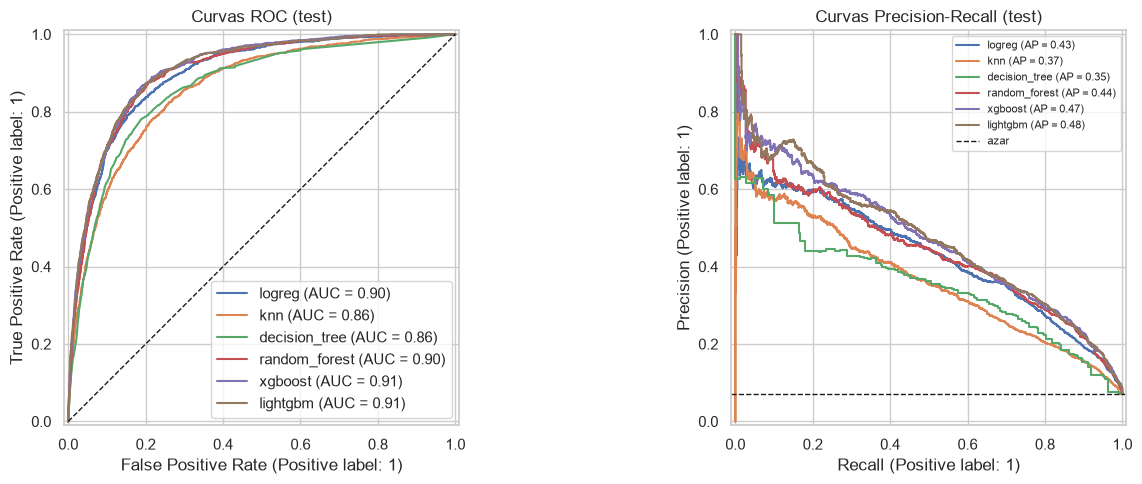

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, m in entrenados.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax[0], name=name)
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, ax=ax[1], name=name)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("Curvas ROC (test)")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="azar"); ax[1].set_title("Curvas Precision-Recall (test)")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Modelo final y umbral de decisión

Por defecto se clasifica como éxito si la probabilidad ≥ 0,5, pero con clases desbalanceadas ese umbral no suele ser el óptimo.
Elegimos el umbral que **maximiza el F1** usando predicciones *out-of-fold* del **train** (así el test sigue sin tocarse).

Modelo final: xgboost
Umbral óptimo (F1 en train OOF): 0.774


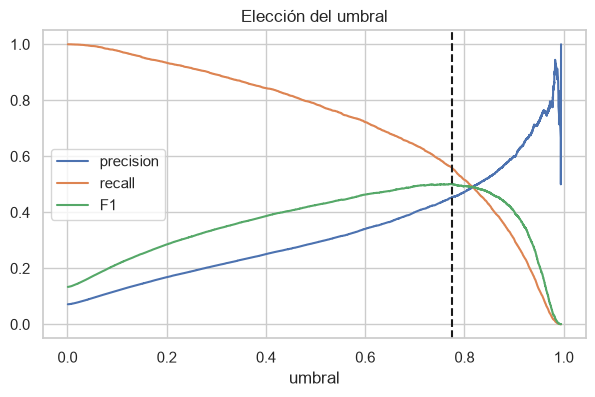

In [10]:
FINAL = res.drop(index=["dummy", "logreg_base"]).index[0]
final_model = entrenados[FINAL]
print("Modelo final:", FINAL)

oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
THR = float(thr[np.argmax(f1[:-1])])
print(f"Umbral óptimo (F1 en train OOF): {THR:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label="precision"); plt.plot(thr, rec[:-1], label="recall"); plt.plot(thr, f1[:-1], label="F1")
plt.axvline(THR, color="k", ls="--"); plt.xlabel("umbral"); plt.legend(); plt.title("Elección del umbral")
plt.show()

PR_AUC        0.470
ROC_AUC       0.907
precision     0.436
recall        0.569
F1            0.494
prec@top1%    0.713
prec@top5%    0.549
dtype: float64
              precision    recall  f1-score   support

  No exitoso       0.97      0.94      0.95     14593
     Exitoso       0.44      0.57      0.49      1126

    accuracy                           0.92     15719
   macro avg       0.70      0.76      0.72     15719
weighted avg       0.93      0.92      0.92     15719



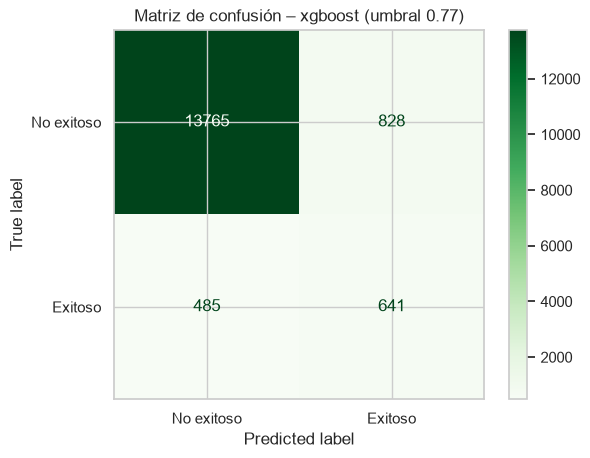

In [11]:
final_metrics = evaluate(final_model, X_test, y_test, thr=THR)
print(pd.Series(final_metrics).round(3))

proba_test = final_model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, (proba_test >= THR).astype(int), target_names=["No exitoso", "Exitoso"]))
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= THR).astype(int),
                                        display_labels=["No exitoso", "Exitoso"], cmap="Greens")
plt.title(f"Matriz de confusión – {FINAL} (umbral {THR:.2f})"); plt.show()

### 7.1 Lectura de negocio: ¿cuánto mejora el modelo frente a elegir al azar?

Ordenamos los juegos del test por probabilidad y los agrupamos en deciles. Si un publisher/inversor solo revisa el **10 % de juegos mejor puntuados**, ¿qué % de éxito encuentra frente al 7 % de base?

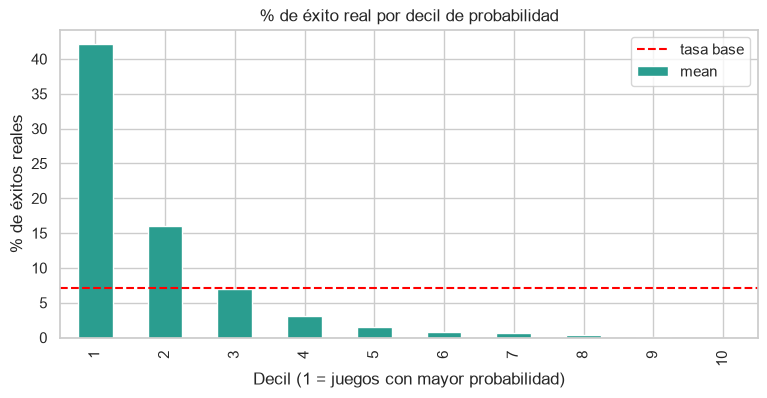

Decil 1: 42.1% de éxitos (x5.9 vs azar)
El top 20% de juegos concentra el 81% de todos los éxitos


In [12]:
dec = pd.DataFrame({"proba": proba_test, "y": y_test.values})
dec["decil"] = pd.qcut(dec["proba"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = dec.groupby("decil", observed=True)["y"].agg(["mean", "sum"])
lift["lift"] = lift["mean"] / y_test.mean()

fig, ax = plt.subplots(figsize=(9, 4))
(lift["mean"] * 100).plot.bar(ax=ax, color="#2a9d8f")
ax.axhline(y_test.mean() * 100, color="red", ls="--", label="tasa base")
ax.set_xlabel("Decil (1 = juegos con mayor probabilidad)"); ax.set_ylabel("% de éxitos reales")
ax.set_title("% de éxito real por decil de probabilidad"); ax.legend(); plt.show()

pct_capturado = lift["sum"].iloc[:2].sum() / lift["sum"].sum() * 100
print(f"Decil 1: {lift['mean'].iloc[0]*100:.1f}% de éxitos (x{lift['lift'].iloc[0]:.1f} vs azar)")
print(f"El top 20% de juegos concentra el {pct_capturado:.0f}% de todos los éxitos")

## 8. Interpretación: ¿qué variables pesan más?

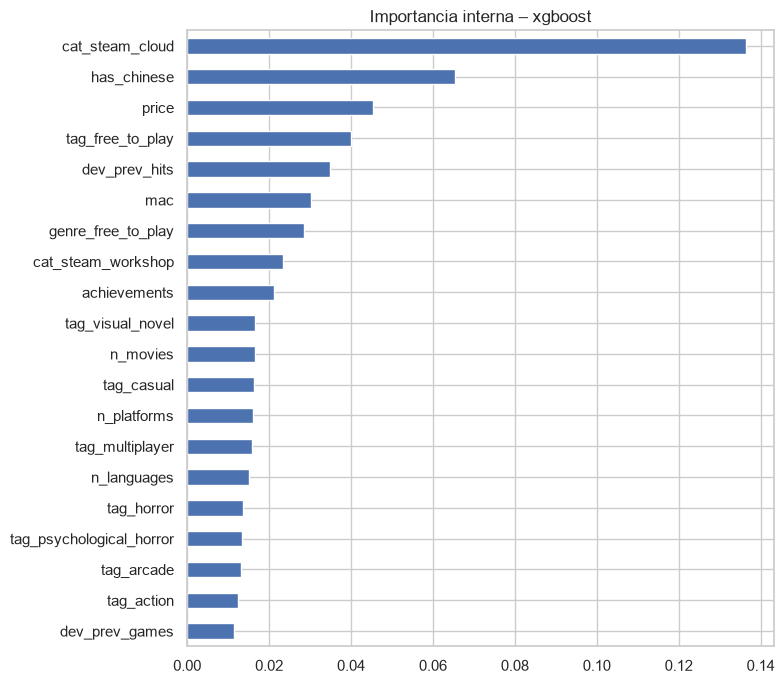

In [13]:
feat_names = final_model.named_steps["prep"].get_feature_names_out()
clf = final_model.named_steps["clf"]

if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=feat_names)
elif hasattr(clf, "coef_"):
    imp = pd.Series(np.abs(clf.coef_[0]), index=feat_names)
else:
    imp = None

if imp is not None:
    imp.sort_values().tail(20).plot.barh(figsize=(8, 7), title=f"Importancia interna – {FINAL}")
    plt.tight_layout(); plt.show()

La importancia interna de los árboles puede sesgarse hacia variables con muchos valores distintos.
La **permutation importance** es más fiable: mide cuánto cae la PR-AUC en test si "desordenamos" cada variable.

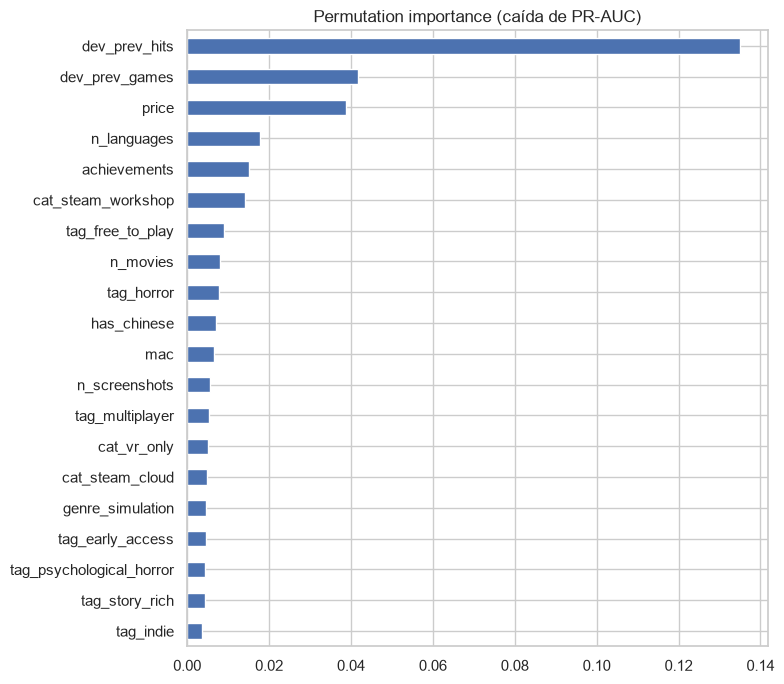

In [14]:
sample = X_test.sample(min(5000, len(X_test)), random_state=RS)
pi = permutation_importance(final_model, sample, y_test.loc[sample.index], scoring="average_precision",
                            n_repeats=5, random_state=RS, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
perm.tail(20).plot.barh(figsize=(8, 7), title="Permutation importance (caída de PR-AUC)")
plt.tight_layout(); plt.show()

### 8.1 (Opcional) SHAP: dirección del efecto

Requiere `pip install shap`. Muestra no solo qué variables importan, sino **si suben o bajan** la probabilidad de éxito.

c:\Users\TB Val 13\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


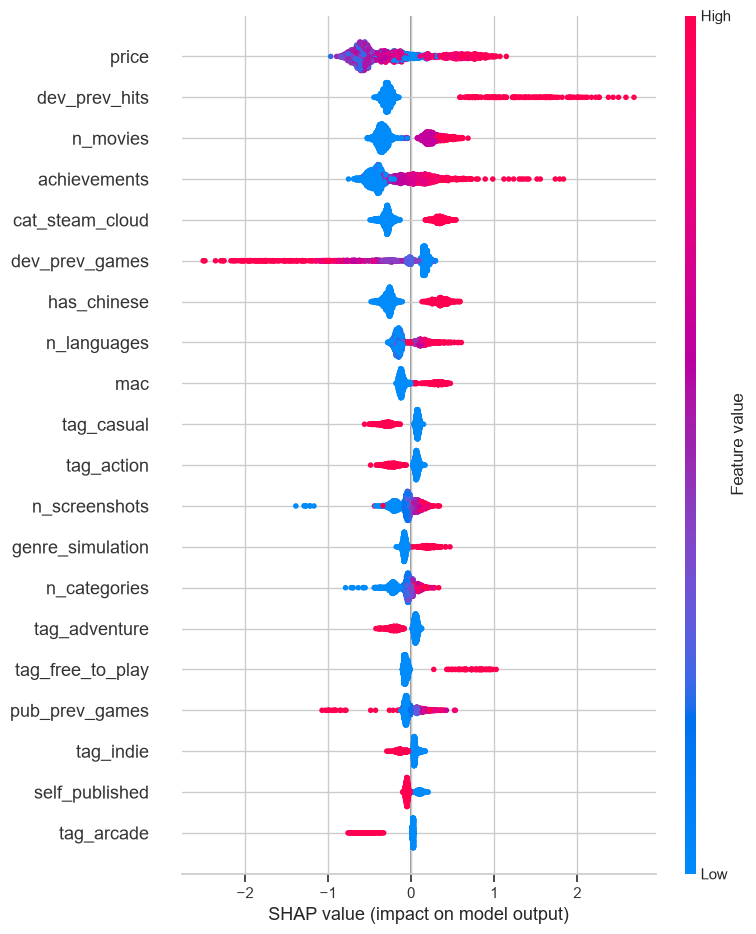

In [15]:
try:
    import shap
    Xs = final_model.named_steps["prep"].transform(sample.iloc[:2000])
    explainer = shap.TreeExplainer(clf)
    sv = explainer.shap_values(Xs)
    sv = sv[1] if isinstance(sv, list) else sv
    shap.summary_plot(sv, pd.DataFrame(Xs, columns=feat_names), max_display=20)
except Exception as e:
    print("SHAP no disponible para este modelo/entorno:", e)

### 8.2 Análisis de robustez: ¿depende demasiado del historial del desarrollador?

In [17]:
from sklearn.base import clone

ESCENARIOS = {
    "todas las features": [],
    "sin dev_prev_hits": ["dev_prev_hits"],
    "sin historial dev/pub": ["dev_prev_hits", "dev_prev_games", "pub_prev_games"],
}
abl = []
for nombre, quitar in ESCENARIOS.items():
    Xtr, Xte = X_train.copy(), X_test.copy()
    Xtr[quitar] = 0          # anular la variable = quitarle toda la información
    Xte[quitar] = 0
    m = clone(final_model).fit(Xtr, y_train)
    abl.append({"escenario": nombre, **evaluate(m, Xte, y_test)})

# ¿Qué tal funciona con estudios debutantes (sin juegos previos)?
nuevo = X_test["dev_prev_games"] == 0
p = final_model.predict_proba(X_test[nuevo])[:, 1]
print(f"Estudios debutantes: {nuevo.mean()*100:.0f}% del test | % éxito real {y_test[nuevo].mean()*100:.1f}% "
      f"| PR-AUC {average_precision_score(y_test[nuevo], p):.3f}")

pd.DataFrame(abl).set_index("escenario")[["PR_AUC", "ROC_AUC", "prec@top1%", "prec@top5%"]].round(3)

Estudios debutantes: 60% del test | % éxito real 5.6% | PR-AUC 0.389


,PR_AUC,ROC_AUC,prec@top1%,prec@top5%
escenario,,,,
todas las features,0.470,0.907,0.713,0.549
sin dev_prev_hits,0.430,0.891,0.618,0.522
sin historial dev/pub,0.428,0.891,0.637,0.526


## 9. Guardado del modelo final

In [18]:
joblib.dump(final_model, MODELS / "final_model.pkl")
with open(MODELS / "final_model_meta.json", "w", encoding="utf-8") as f:
    json.dump({"modelo": FINAL, "umbral": THR, "features": FEATURES,
               "metricas_test": {k: round(float(v), 4) for k, v in final_metrics.items()},
               "best_params": {k: str(v) for k, v in final_model.get_params().items() if k.startswith("clf__")
                               and k.replace("clf__", "") in str(MODELOS[FINAL][1])}},
              f, ensure_ascii=False, indent=2)
print("Guardado models/final_model.pkl")

Guardado models/final_model.pkl


## 10. Conclusiones

*(Rellenar tras ejecutar)*

- Mejor modelo y PR-AUC (CV y test) frente al baseline: …
- Umbral elegido y qué significa (precision / recall): …
- Lectura de negocio: el decil 1 tiene un … % de éxitos (x… respecto al azar).
- Variables más influyentes y su interpretación: …
- Limitaciones: …